# Wikipedia API

<!--<badge>--><a href="https://colab.research.google.com/github/kuennethgroup/ml_in_ms_wt26/blob/main/03_ex/wikipedia_api.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a><!--</badge>-->

Here you learn how to use the Wikipedia API to retrieve information about materials. The Wikipedia API allows you to programmatically access and extract data from Wikipedia articles.

In [2]:
from pprint import pprint
import wikipediaapi

wiki_wiki = wikipediaapi.Wikipedia("MyProjectName (bla@bla.com)", "en")

page_py = wiki_wiki.page("Polyethylene_glycol")
print(page_py.text)

Polyethylene glycol (PEG; ) is a polyether compound derived from petroleum with many applications, from industrial manufacturing to medicine. PEG is also known as polyethylene oxide (PEO) or polyoxyethylene (POE), depending on its molecular weight. The structure of PEG is commonly expressed as H−(O−CH2−CH2)n−OH.
PEG is commonly incorporated into hydrogels which present a functional form for further use.

Uses
Medical
Pharmaceutical-grade PEG is used as an excipient in many pharmaceutical products, in oral, topical, and parenteral dosage forms.
PEG is the basis of a number of laxatives (as MiraLax, RestoraLAX, MoviPrep, etc.). Macrogol (with brand names such as Laxido, Movicol and Miralax) is the generic name for polyethylene glycol used as a laxative. The name may be followed by a number that represents the average molecular weight (e.g. macrogol 3350, macrogol 4000, or macrogol 6000). Whole bowel irrigation with polyethylene glycol and added electrolytes is used for bowel preparation 

In [3]:
# Get pages related to polymers
def get_polymer_pages(category_title):
    """Retrieve all pages from a specific category in Wikipedia"""
    category = wiki_wiki.page(f"Category:{category_title}")

    if not category.exists():
        print(f"Category '{category_title}' does not exist on Wikipedia")
        return {}

    polymer_pages = {}
    for page_name in category.categorymembers.keys():
        page = wiki_wiki.page(page_name)
        # Store only regular pages (not categories, etc.)
        if page.namespace == 0:
            polymer_pages[page_name] = page

    return polymer_pages


# Get polymer-related pages
polymer_pages = get_polymer_pages("Polymers")

# Wordcloud

1. Iteratively retrieve data for https://en.wikipedia.org/wiki/Polyethylene_glycol, https://en.wikipedia.org/wiki/Polyethylene, https://en.wikipedia.org/wiki/Polyethylene_terephthalate, and https://en.wikipedia.org/wiki/Acrylonitrile_butadiene_styrene
2. Create a dictionary that contains {`Polyethylene_glycol`: `wiki_text`, ...}

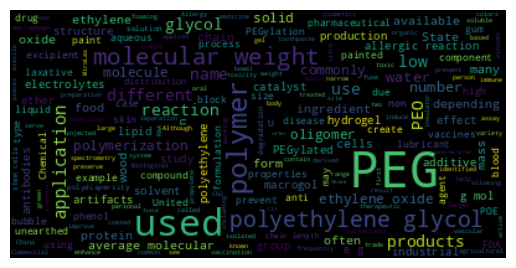

In [4]:
#!pip install wordcloud

from wordcloud import WordCloud

# Display the generated image:
import matplotlib.pyplot as plt

# Generate a word cloud image
# lower max_font_size
wordcloud = WordCloud(
    max_font_size=40,
).generate(page_py.text)
plt.figure()
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

# Exercise
1. Generate one word cloud for each of the 4 Wikipedia articles (above) and one word cloud based on all 4 articles.